#### Importing MNIST dataset

In [4]:
from tensorflow.keras.datasets import mnist

#### Importing Libraries for Model.

In [5]:
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical

#### Loading the MNIST dataset

In [6]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

#### Data Normalization

In [7]:
x_train = x_train/255
x_test = x_test/255
y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)

#### Ploting the One index of dataset

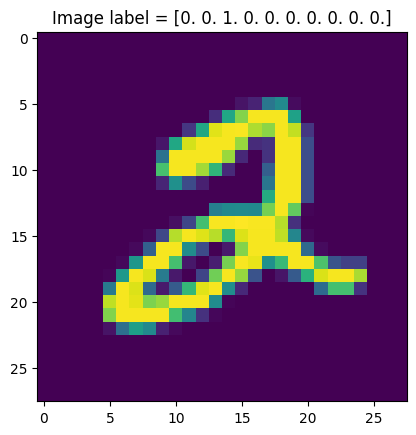

In [8]:
import matplotlib.pyplot as plt
plt.imshow(x_train[5])
plt.title(f"Image label = {y_train[5]}")
plt.show()

#### Creating Model

In [9]:
model = Sequential([
    Flatten(input_shape = (28, 28)), # input layer = 784 neurons
    Dense(128, activation= 'relu'), # hidden layer 128 neuron
    Dense(10, activation= 'softmax') # output layer 10 neuron because we have 0-9 numbers
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


#### Model Summary

In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

#### Model Compiling

In [11]:
model.compile(
    optimizer = 'adam',
    loss = 'categorical_crossentropy',
    metrics = ['accuracy']
)

#### Fit the Model

In [12]:
model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    verbose=2
)

Epoch 1/5
1875/1875 - 5s - 3ms/step - accuracy: 0.9263 - loss: 0.2572
Epoch 2/5
1875/1875 - 4s - 2ms/step - accuracy: 0.9661 - loss: 0.1154
Epoch 3/5
1875/1875 - 4s - 2ms/step - accuracy: 0.9753 - loss: 0.0803
Epoch 4/5
1875/1875 - 4s - 2ms/step - accuracy: 0.9811 - loss: 0.0599
Epoch 5/5
1875/1875 - 4s - 2ms/step - accuracy: 0.9854 - loss: 0.0474


#### Evalute the model

In [13]:
model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9754 - loss: 0.0821


[0.08213507384061813, 0.9753999710083008]

#### Save the model

In [16]:
model.save("mnist.keras")